In [1]:
import numpy as np
from numpy.polynomial.legendre import leggauss
from scipy.interpolate import BSpline
from scipy.integrate import quad, fixed_quad
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize
import pandas as pd
from matplotlib import pyplot as plt

import lhapdf

## Load Precomputed FK Table

In [2]:
# load data from output of data_T3.py
data = np.load("Dataset/data_208.npz")

# Access individual arrays
Q0        = data["Q0"]
q2_vals   = data["q2_vals"]
y_vals    = data["y_vals"]
grid      = data["grid"]
xt3_grid  = data["xt3_grid"]
t3_grid   = data["t3_grid"]
T_theory  = data["T_theory"]
xT_theory = data["xT_theory"]
D         = data["D"]
W         = data["W"]
Sigma      = data["Sigma"]
xQ2 = data["kinematics"]

## Helper Functions

In [3]:
# Build B-spline basis on [0,1]
def bspline_basis(degree, M, a, b):
    """
    Parameters
    ----------
    degree: degree of B-splines
    M: number of basis functions
    a, b: interval endpoints
    """

    # knots
    n_internal = M - degree - 1
    if n_internal > 0:
        inner_knots = np.linspace(a, b, n_internal + 2)[1:-1]
    else:
        inner_knots = np.array([])
    knots = np.r_[np.repeat(a, degree + 1), inner_knots, np.repeat(b, degree + 1)]
    #print("knots: ", knots)

    # basis functions
    I = np.eye(M)
    B = [BSpline(knots, I[m], degree, extrapolate=False) for m in range(M)]
    return B


# ----------------------------
# Helpers for (x,Q2) pairs
# ----------------------------
def _as_pairs(xQ2):
    """
    Normalize input into an (n,2) float array of (x, Q2).
    Accepts:
      - array-like shape (n,2)
      - tuple/list (x_array, Q2_array) with same length
    """
    if isinstance(xQ2, (tuple, list)) and len(xQ2) == 2 and np.ndim(xQ2[0]) > 0:
        x = np.asarray(xQ2[0], dtype=float)
        Q2 = np.asarray(xQ2[1], dtype=float)
        if x.shape != Q2.shape:
            raise ValueError(f"x and Q2 must have same shape, got {x.shape} vs {Q2.shape}")
        return np.column_stack([x.ravel(), Q2.ravel()]).astype(float)

    arr = np.asarray(xQ2, dtype=float)
    if arr.ndim != 2 or arr.shape[1] != 2:
        raise ValueError(f"xQ2 must have shape (n,2), got {arr.shape}")
    return arr


def _validate_x(x, idx=None):
    if x <= 0.0:
        where = f" at index {idx}" if idx is not None else ""
        raise ValueError(f"x must be in (0,1], got x={x}{where}.")


## Wilson Coefficients and Theory Predictions

In [4]:
# Determine Lambda, Q2_min, Q2_max from the data
Lambda = 500
Q2_min = np.min(xQ2[:, 1])
Q2_max = np.max(xQ2[:, 1])

In [5]:
def klin(z, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max):
    z = np.asarray(z, dtype=float)
    return 1/(Lambda**2) * ((z - Q2_min)**2) / ((Q2_max - Q2_min)**2)

def kquad(z, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max):
    z = np.asarray(z, dtype=float)
    return 1/(Lambda**4) * ((z - Q2_min)**2) / ((Q2_max - Q2_min)**2)

def v_c(c, xQ2, klin=klin, kquad=kquad):
    xQ2 = _as_pairs(xQ2)
    Q2 = xQ2[:, 1]
    return 1.0 + klin(Q2) * c + kquad(Q2) * (c**2)

def v_prime_c(c, xQ2, klin=klin, kquad=kquad):
    xQ2 = _as_pairs(xQ2)
    Q2 = xQ2[:, 1]
    return klin(Q2) + 2.0 * c * kquad(Q2)


In [6]:
# Here, we build the design matrix A as well as theory predictions based on FK tables and datasets.
def build_f_design_matrix_FK(B, W, grid):
    """
    Build the design matrix A using FK tables, where the convolution is represented as a matrix multiplication with W.

    Parameters
    ----------
    B : list of m basis functions, each B_k is a callable B_k(y)
    W : (N_data, N_grid) matrix from FK table representing the convolution
    grid, (N_grid) array of y values corresponding to the columns of W

    Returns
    -------
    A : (N_data, m) array
        Design matrix where A[r,k] = ∫ sigma(x_r/y, Q2_r) * B_k(y) dy = W @ B_grid.T.
    """

    # Evaluate basis functions on the grid points corresponding to W
    B_grid = np.vstack([Bk(grid) for Bk in B])  # shape (m, n_grid)

    # The design matrix A is then given by the convolution of W with the basis functions evaluated on the grid
    A = W @ B_grid.T  # shape (N_data, m)

    return A

def build_yf_design_matrix_FK(B, W, grid):
    """
    Build the design matrix A for the parameterization g(y) = y f(y) = sum_k theta_k B_k(y),
    using FK tables.

    Parameters
    ----------
    B : list of m basis functions, each B_k is a callable B_k(y)
    W : (N_data, N_grid) matrix from FK table representing the convolution with f(y)
    grid, (N_grid) array of y values corresponding to the columns of W

    Returns
    -------
    A : (N_data, m) array
        Design matrix where A[r,k] = ∫ sigma(x_r/y, Q2_r) * B_k(y) dy = W @ (B_grid.T / grid).
    """

    # Evaluate basis functions on the grid points corresponding to W
    B_grid = np.vstack([Bk(grid) for Bk in B])  # shape (m, n_grid)

    # The design matrix A is then given by the convolution of W with the basis functions evaluated on the grid, divided by y
    A = W @ (B_grid.T / grid[:, np.newaxis])  # shape (N_data, m)

    return A

def build_K_matrix(c, A, xQ2, klin, kquad):
    """
    Build the K matrix which is a diagonal matrix with v_c(c, xQ2) on the diagonal, multiplied by A.
    """
    v = v_c(c, xQ2, klin=klin, kquad=kquad)
    return np.diag(v) @ A

def build_K_prime_matrix(c, A, xQ2, klin, kquad):
    """
    The derivative of K with respect to c, which is a diagonal matrix with v_prime_c(c, xQ2) on the diagonal, multiplied by A.
    """

    v_prime = v_prime_c(c, xQ2, klin=klin, kquad=kquad)
    return np.diag(v_prime) @ A

def T_sm_FK(f, W, grid):
    """
    Compute T_SM using FK tables, where f is the PDF function and W is the convolution matrix.
    
    Parameters
    ----------
    f : callable
        The PDF function
    W : (N_data, N_grid) matrix from FK table representing the convolution
    grid : (N_grid) array of y values corresponding to the columns of W

    Returns
    -------
    T_vec : (N_data) array
        The standard model predictions.
    """
    # Evaluate PDF on the grid
    f_grid = f(grid)  # shape (N_grid,)

    # Compute T_vec
    T_vec = W @ f_grid  # shape (N_data,)

    return T_vec

def T_sm_basis(A, beta):
    """
    Compute theory predictions T_SM using the design matrix A and coefficients beta.
    """
    return A @ beta

def true_mean(c, T, xQ2, klin, kquad):
    """
    Compute the true mean predictions by multiplying the standard model predictions T with the polynomial factor v_c(c, xQ2).
    """
    v = v_c(c, xQ2, klin=klin, kquad=kquad)
    return v * T

def true_mean_basis(c, beta, A, xQ2, klin, kquad):
    """
    Compute the true mean predictions given the coefficients beta for the basis expansion, the design matrix A, and the polynomial factor v_c(c, xQ2).
    """
    v = v_c(c, xQ2, klin=klin, kquad=kquad)        
    T = T_sm_basis(A, beta)
    return v * T

## Likelihood and Fitting Functions

In [7]:
# Negative log-likelihood and gradient
def make_nll_and_grad(D, A, v, v_prime, xQ2, Sigma=None):
    """
    D     : (N,) data vector
    A     : (N, M) matrix from T(f) (T(f) = A @ beta)
    v     : callable     v(c) returns (N,) vector
    v_prime: callable    v_prime(c) returns (N,) vector (derivative of v)
    xQ2: (n, 2) array of (x,Q2) pairs
    Sigma : (N, N) known covariance (default None; identity matrix)
    """
    N, M = A.shape

    if Sigma is not None:
        # Cholesky factorization of Sigma
        cF, lower = cho_factor(Sigma, check_finite=False)
        def Sigma_inv(v):    # Sigma^{-1} v
            return cho_solve((cF, lower), v, check_finite=False)
    else:
        def Sigma_inv(v):
            return v


    def nll(theta):
        beta = theta[:M]
        c = theta[-1]
        vc = v(c, xQ2=xQ2)
        mu = vc * (A @ beta)
        r = D - mu
        #loss = 0.5 * r @ r
        loss = 0.5 * r @ Sigma_inv(r)

        return loss

    def grad(theta):
        beta = theta[:M]
        c = theta[-1]

        vc = v(c, xQ2=xQ2)
        dv = v_prime(c, xQ2=xQ2)
        mu = vc * (A @ beta)         
        r = D - mu
        Sigma_inv_r = Sigma_inv(r)

        # d(NLL)/d beta = - (diag(v(c)) A)^T Sigma^{-1} r
        g_beta = - ((vc[:, None] * A).T @ Sigma_inv_r)

        # d(NLL)/d c = - (dv(c) \odot (A beta))^T Sigma^{-1} r
        g_c = - (dv * (A @ beta)).T @ Sigma_inv_r

        return np.r_[g_beta, g_c]

    return nll, grad


def fit_beta_c(D, A, v, v_prime, w_norm, xQ2, Sigma=None, beta0=None, c0=0.0,
               nonneg_beta=False, return_history=False, opt_method="SLSQP", loss_scale=1):
    """
    Fit parameters beta and c by joint minimization of the negative log-likelihood.
    
    D     : (N,) data vector
    A     : (N, M) matrix from T(f) (T(f) = A @ beta)
    v     : callable     v(c) returns (N,) vector
    v_prime: callable    v_prime(c) returns (N,) vector (derivative of v)
    w_norm: (M,) normalization weights, int B_m(y) dy
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N) known covariance (default None; identity matrix)
    beta0 : (M,) initial guess for beta (optional)
    c0    : initial guess for c (default 0.0)
    nonneg_beta : if True, enforce beta >= 0 (default False)
    return_history : if True, return (res, history) where history is a list of per-iteration dicts
    opt_method : optimization method to use (default "SLSQP")
    loss_scale : scale factor for the loss function (default 1)
    """
   
    N, M = A.shape
    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(M)
        if nonneg_beta:
            b = np.abs(b)  # make it nonnegative to help optimization if nonneg_beta is True
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)
    #print("initial beta:", beta0)
    #print("w_norm:", w_norm)
    # check the normalization constraint is satisfied by the initial beta0
    if abs(w_norm @ beta0 - 1.0) > 1e-10:
        print("Initial beta0 does not satisfy the normalization constraint: w_norm @ beta0 =", w_norm @ beta0)
    if nonneg_beta and np.any(beta0 < 0):
        print("Initial beta0 has negative entries.")

    theta0 = np.r_[beta0, c0]

    nll, grad = make_nll_and_grad(D, A, v, v_prime, xQ2=xQ2, Sigma=Sigma)

    #loss_scale = max(abs(nll(theta0)), 1.0)
    # so far this scaling seems to make optimization more stable, but it's a bit ad-hoc.
    #loss_scale = 1
    def nll_scaled(theta):
        return nll(theta) / loss_scale

    def grad_scaled(theta):
        return grad(theta) / loss_scale

    #from scipy.optimize import check_grad
    #err = check_grad(nll_scaled, grad_scaled, theta0)
   # print("Gradient check error:", err) 

    # Equality constraint: w_norm^T beta = 1
    cons = [{
        "type": "eq",
        "fun":  lambda x: float(w_norm @ x[:M] - 1.0),
        "jac":  lambda x: np.r_[w_norm, 0.0]
    }]


    if return_history:
        history = []

    def callback(theta, state=None):
        if return_history:
            history.append({
                'loss': float(state.fun) if state is not None else float(nll_scaled(theta)),
                'constr_viol': float(state.constr_violation)
                                if state is not None else float(abs(w_norm @ theta[:M] - 1.0)),
                'grad_norm': float(state.optimality)
                            if state is not None else float(np.linalg.norm(grad_scaled(theta))),
                'beta_norm': float(np.linalg.norm(theta[:M])),
                'c': float(theta[-1]),
            })

    # Bounds:
    if nonneg_beta:
        bounds = [(0.0, None)] * M + [(None, None)]
    else:
        bounds = [(None, None)] * (M + 1)

    _callback = callback if return_history else None

    if opt_method == "SLSQP":
        options = dict(maxiter=5000, ftol=1e-10)
    elif opt_method == "trust-constr":
        options = dict(maxiter=5000, gtol=1e-10)
    else:
        raise ValueError(f"Unsupported optimization method: {opt_method}")

    res = minimize(nll_scaled, theta0, jac=grad_scaled, method=opt_method,
                   constraints=cons, bounds=bounds,
                   options=options,
                   callback=_callback)
    
    num_try = 10
    while not res.success and num_try > 0:
        # try it again with different init
        b = np.random.rand(M)
        if nonneg_beta:
            b = np.abs(b)  # make it nonnegative to help optimization if nonneg_beta is True
        beta0 = b / (w_norm @ b)
        theta0 = np.r_[beta0, c0]
        history.clear()
        res = minimize(nll_scaled, theta0, jac=grad_scaled, method=opt_method,
                constraints=cons, bounds=bounds,
                options=options,
                callback=_callback)
        num_try -= 1
    if not res.success:
        print(f"Optimization failed: {res.message}")
    res.beta_hat = res.x[:M]
    res.c_hat = res.x[-1]

    if return_history:
        return res, history
    return res


def mle_beta(D, A, c, v, xQ2, w_norm, Sigma=None, beta0=None, nonneg_beta=True, 
             beta_opt="SLSQP", return_history=False, loss_scale=1):
    """
    Find MLE of beta given c

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    c : float        given value of c
    v : callable     v(c) returns (N,) vector
    xQ2: (N, 2) array of (x,Q2) pairs
    w_norm: (M,)     normalization weights, int B_m(y) dy
    Sigma : (N, N)   covariance (PD). If None, assume identity matrix
    beta0 : (M,)     initial guess for beta (optional)
    nonneg_beta :    if True, enforce beta >= 0 (default False)
    beta_opt: str    optimization method for beta ("SLSQP", "trust-constr" or "closed_form")
    return_history: bool if True, return (beta_hat, history) where history is a list of per-iteration dicts (only for optimization-based methods)
    loss_scale: scale factor for the loss function (default 1)

    Returns
    -------
    beta_hat : (M,)  MLE of beta given c
    """

    N, M = A.shape

    # Sigma^{-1} v
    if Sigma is not None:
        cF, lower = cho_factor(Sigma, check_finite=False)
        Sigma_inv = lambda v: cho_solve((cF, lower), v, check_finite=False)
    else:
        Sigma_inv = lambda v: v

    vc = v(c, xQ2=xQ2)

    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(M)
        if nonneg_beta:
            b = np.abs(b)  # make it nonnegative to help optimization if nonneg_beta is True
        #b = np.ones(M)  # start with uniform beta
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)
    if abs(w_norm @ beta0 - 1.0) > 1e-10:
        print("Initial beta0 does not satisfy the normalization constraint: w_norm @ beta0 =", w_norm @ beta0)
    if nonneg_beta and np.any(beta0 < 0):
        print("Initial beta0 has negative entries.")

    if beta_opt == "SLSQP" or beta_opt == "trust-constr":
        # solve beta via constrained optimization
        def loss(beta):
            mu = vc * (A @ beta)
            r  = D - mu
            return 0.5 * r @ Sigma_inv(r)

        def grad(beta):
            mu = vc * (A @ beta)
            r  = D - mu
            # gradient of 0.5 * r^T S^{-1} r w.r.t beta
            return -(vc[:, None] * A).T @ Sigma_inv(r)

        #loss_scale = 1
        def loss_scaled(beta):
            return loss(beta) / loss_scale
        def grad_scaled(beta):
            return grad(beta) / loss_scale

        cons = {'type': 'eq',
                'fun': lambda beta: float(w_norm @ beta - 1.0),
                'jac': lambda beta: w_norm}
        
        # Bounds:
        if nonneg_beta:
            bounds = [(0.0, None)] * M
        else:
            bounds = [(None, None)] * M

        if return_history:
            history = []

        def callback(theta, state=None):
            if return_history:
                history.append({
                    'loss': float(state.fun) if state is not None else float(loss_scaled(theta)),
                    'constr_viol': float(state.constr_violation)
                                    if state is not None else float(abs(w_norm @ theta[:M] - 1.0)),
                    'grad_norm': float(state.optimality)
                                if state is not None else float(np.linalg.norm(grad_scaled(theta))),
                    'beta_norm': float(np.linalg.norm(theta[:M])),
                    'c': float(theta[-1]),
                })

        if beta_opt == "SLSQP":
            options = dict(maxiter=5000, ftol=1e-10)
        elif beta_opt == "trust-constr":
            options = dict(maxiter=5000, gtol=1e-10)

        res = minimize(loss_scaled, beta0, jac=grad_scaled, method=beta_opt, constraints=cons, bounds=bounds,
                       callback=callback, options=options)
        
        num_try = 10
        while not res.success and num_try > 0:
            # try it again with different init
            b = np.random.rand(M)
            # normalize w^T b = 1
            beta0 = b / (w_norm @ b)
            history.clear()
            res = minimize(loss_scaled, beta0, jac=grad_scaled, method=beta_opt, constraints=cons, bounds=bounds,
                       callback=callback, options=dict(maxiter=1000, ftol=1e-10))
            num_try -= 1
        
        if not res.success:
            print(f"Optimization for beta failed: {res.message}")
        if return_history:
            return res.x, history
        return res.x
    elif beta_opt == "closed_form":
        # Build W = diag(v(c)) A without forming diag explicitly
        nu = np.asarray(v(c, xQ2=xQ2)).reshape(-1)
        if nu.shape[0] != N:
            raise ValueError(f"v(c) must return shape {(N,)}, got {nu.shape}.")
        W = nu[:, None] * A  # (N, M)

        # U = W^T Sigma^{-1} W,  b = W^T Sigma^{-1} D
        SinvW = np.column_stack([Sigma_inv(W[:, j]) for j in range(M)])  # (N, M)
        U = W.T @ SinvW                                                  # (M, M)
        b = W.T @ Sigma_inv(D)                                           # (M,)

        # Solve KKT system:
        # [U  w] [beta]   [b]
        # [w^T 0] [lam ] = [1]
        KKT = np.zeros((M + 1, M + 1), dtype=float)
        KKT[:M, :M] = U
        KKT[:M, M] = w_norm
        KKT[M, :M] = w_norm
        rhs = np.zeros(M + 1, dtype=float)
        rhs[:M] = b
        rhs[M] = 1.0
    
        sol = np.linalg.solve(KKT, rhs)

        beta_hat = sol[:M]
        if nonneg_beta and np.any(beta_hat < 0):
            raise ValueError("Closed-form beta has negative entries; try using 'SLSQP' or 'trust-constr' option.")
        return beta_hat
    else:
        raise ValueError("Invalid beta_opt method.")

def mle_c(D, A, v, beta, xQ2, Sigma=None, c_opt="scipy_optimize"):
    """
    Find MLE of c given beta

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    v : callable     v(c) returns (N,) vector
    beta : (M,)      given value of beta
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N)   covariance (PD). Use if full matrix.
    c_opt : str      optimization method for c ("scipy_optimize" or "grid_search")
    w_norm: (M,)     normalization weights, int B_m(y) dy

    Returns
    -------
    c_hat : float    MLE of c given v
    """

    N, M = A.shape

    # Fast operator v -> Sigma^{-1} v
    if Sigma is not None:
        cF, lower = cho_factor(Sigma, check_finite=False)
        Sigma_inv = lambda v: cho_solve((cF, lower), v, check_finite=False)
    else:
        Sigma_inv = lambda v: v

    def nll(c):
        vc = v(c, xQ2=xQ2)
        mu = vc * (A @ beta)
        r = D - mu
        loss = 0.5 * r @ Sigma_inv(r)
        return loss


    if c_opt == "scipy_optimize":
        res = minimize(lambda c: nll(c), x0=0.0, method='L-BFGS-B')
        if not res.success:
            res = minimize(lambda c: nll(c), x0=0.0, method='Nelder-Mead')
            if not res.success:
                raise RuntimeError(f"Optimization failed: {res.message}")
        return res.x[0]
    elif c_opt == "grid_search":
        # Simple grid search over a reasonable range of c values
        c_grid = np.linspace(-5.0, 5.0, 1000)
        nll_values = np.array([nll(c) for c in c_grid])
        idx_min = np.argmin(nll_values)
        return c_grid[idx_min]
    else:
        raise ValueError("Invalid c_opt method.")
    


def one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=None, s2_diag=None):
    """
    One-step estimator for c using the EIF with beta nuisance under constraint w_norm^T beta = 1.

    Model:
        mu(c,beta) = K(c) @ beta
        dmu/dc     = K_prime(c) @ beta
    Nuisance tangent restriction:
        beta_e = beta + e h with w_norm^T h = 0.

    Parameters
    ----------
    D       : (N,) data vector
    K       : (N, M) matrix, mu = K @ beta
    K_prime : (N, M) derivative wrt c, dmu/dc = K_prime @ beta
    beta_hat: (M,) estimated beta (ideally satisfies w_norm^T beta_hat ≈ 1)
    c_hat   : float, current estimate of c
    w_norm  : (M,) normalization weights, enforces w_norm^T beta = 1
    Sigma   : (N, N) covariance (optional). If None and s2_diag None => identity.
    s2_diag : (N,) diagonal of Sigma if diagonal (preferred). If provided, Sigma ignored.

    Returns
    -------
    c_one_step : float
    eif        : float
    info       : dict (useful diagnostics)
    """

    D = np.asarray(D).reshape(-1)
    beta_hat = np.asarray(beta_hat).reshape(-1)
    w_norm = np.asarray(w_norm).reshape(-1)
    K = np.asarray(K)
    K_prime = np.asarray(K_prime)

    N, M = K.shape

    if D.shape[0] != N:
        raise ValueError(f"D has length {D.shape[0]} but K has {N} rows.")
    if K_prime.shape != (N, M):
        raise ValueError(f"K_prime must have shape {(N, M)}, got {K_prime.shape}.")
    if beta_hat.shape[0] != M:
        raise ValueError(f"beta_hat has length {beta_hat.shape[0]} but K has {M} cols.")
    if w_norm.shape[0] != M:
        raise ValueError(f"w_norm has length {w_norm.shape[0]} but K has {M} cols.")

    # --- Define Sigma^{-1} operator ---
    if s2_diag is not None:
        s2_diag = np.asarray(s2_diag).reshape(-1)
        if s2_diag.shape[0] != N:
            raise ValueError(f"s2_diag has length {s2_diag.shape[0]} but N={N}.")
        if np.any(s2_diag <= 0):
            raise ValueError("All entries of s2_diag must be positive.")

        # Apply Sigma^{-1} to vector/matrix
        def Sigma_inv(v):
            v = np.asarray(v)
            return v / s2_diag[:, None] if v.ndim == 2 else v / s2_diag
    else:
        if Sigma is None:
            def Sigma_inv(v):
                return np.asarray(v)
        else:
            Sigma = np.asarray(Sigma)
            if Sigma.shape != (N, N):
                raise ValueError(f"Sigma must have shape {(N, N)}, got {Sigma.shape}.")
            cF, lower = cho_factor(Sigma, check_finite=False)
            def Sigma_inv(v):
                return cho_solve((cF, lower), v, check_finite=False)

    # --- Plug-in estimates ---
    mu_hat = K @ beta_hat                  # (N,)
    r_hat = D - mu_hat                     # (N,)
    mu_prime_hat = K_prime @ beta_hat      # (N,)

    # --- Build G = K^T Sigma^{-1} K and b = K^T Sigma^{-1} mu_prime_hat ---
    SinvK = Sigma_inv(K)                   # (N, M)
    #SinvK = K
    U = 2 * K.T @ SinvK                    # (M, M)
    b = 2 * K.T @ Sigma_inv(mu_prime_hat)  # (M,)
    #b = 2 * K.T @ mu_prime_hat             # (M,)

    # --- Constrained optimization: minimize ||mu' - K h||_{Sigma^{-1}}^2 s.t. w^T h = 0 ---
    # KKT:
    # [ U   w ] [h]   [b]
    # [ w^T 0 ] [λ] = [0]
    KKT = np.block([
        [U,          w_norm[:, None]],
        [w_norm[None, :], np.zeros((1, 1))]
    ])
    rhs = np.concatenate([b, np.array([0.0])])

    # Solve KKT conditions.
    try:
        sol = np.linalg.solve(KKT, rhs)
    except np.linalg.LinAlgError:
        sol = np.linalg.lstsq(KKT, rhs, rcond=None)[0]

    # projected nuisance coefficients (satisfies w^T h = 0)
    h_star = sol[:M]
    lam = float(sol[M])

    # delta_hat = (I - Pi) mu_prime_hat
    delta_hat = mu_prime_hat - K @ h_star

    # --- EIF and one-step update ---
    num = float(delta_hat.T @ Sigma_inv(r_hat))
    den = float(delta_hat.T @ Sigma_inv(delta_hat))
    #num = float(delta_hat.T @ r_hat)
    #den = float(delta_hat.T @ delta_hat)

    if not np.isfinite(den) or den <= 0:
        print(f"Invalid EIF denominator (information): den={den}. "
                           "This suggests non-identifiability or numerical issues.")

    eif = num / den
    c_one_step = float(c_hat + eif)

    info = {
        "c_hat": c_hat,
        "num": num,
        "den": den,
        "eif": eif,
        "lambda": lam,
        "w_dot_beta": float(w_norm @ beta_hat),
        "w_dot_h": float(w_norm @ h_star),
    }

    return c_one_step, info


## Plotting Functions

In [8]:
def plot_by_Q2(
    Y,
    xQ2,                         # shape (n_pts, 2): columns are (x, Q2)
    ncols=2,
    y_label="Value",
    x_log_scale=False,
    series_styles=None,
    default_style=None,
    show_legend=True,
    sort_x_within_panel=True,
    q2_round_decimals=12,        # helps group nearly-equal floating Q2s
):
    """
    Plot one or multiple vectorized series by Q^2 panels using explicit (x,Q2) pairs.

    Parameters
    ----------
    Y : array-like, list/tuple of array-like, or dict[str, array-like]
        Each series must be length n_pts, aligned with xQ2 rows.
    xQ2 : array-like, shape (n_pts, 2)
        Rows are (x, Q2) pairs in the same order as Y vectors.
    ncols : int
        Number of subplot columns.
    y_label : str
        Y-axis label for each panel.
    x_log_scale : bool
        Use log scale for x-axis (default False).
    series_styles : dict, optional
        Per-series style dict. Each may include 'kind' in {"line","scatter"} plus matplotlib kwargs.
    default_style : dict, optional
        Default style dict; may include 'kind'.
    show_legend : bool
        Show legend (only in the first panel by default).
    sort_x_within_panel : bool
        Sort points by x within each Q2 panel before plotting.
    q2_round_decimals : int
        Q2 grouping key uses round(Q2, q2_round_decimals) to avoid float-equality issues.

    Notes
    -----
    - If a given Q2 has repeated x values, line plots will connect them in sorted order.
      If that's undesirable, use kind="scatter" for that series.
    """
    xQ2 = np.asarray(xQ2, dtype=float)
    if xQ2.ndim != 2 or xQ2.shape[1] != 2:
        raise ValueError(f"xQ2 must have shape (n_pts, 2), got {xQ2.shape}")

    x = xQ2[:, 0]
    Q2 = xQ2[:, 1]
    n_pts = xQ2.shape[0]

    # Normalize Y into list of (label, vec)
    series = []
    if isinstance(Y, dict):
        for lab, vec in Y.items():
            series.append((lab, np.asarray(vec, dtype=float)))
    elif isinstance(Y, (list, tuple)):
        for i, vec in enumerate(Y):
            series.append((f"Y{i+1}", np.asarray(vec, dtype=float)))
    else:
        series = [("Y", np.asarray(Y, dtype=float))]

    # Validate lengths
    for lab, vec in series:
        if vec.size != n_pts:
            raise ValueError(f"Series '{lab}' has length {vec.size}, expected {n_pts}.")

    if series_styles is None:
        series_styles = {}
    if default_style is None:
        default_style = dict(kind="line", linewidth=2)

    # Group by (rounded) Q2
    Q2_key = np.round(Q2, q2_round_decimals)
    uniq_keys = np.unique(Q2_key)

    # Keep a stable ordering by increasing actual Q2 (using mean within group)
    q2_values = []
    idx_groups = []
    for k in uniq_keys:
        idx = np.where(Q2_key == k)[0]
        idx_groups.append(idx)
        q2_values.append(np.mean(Q2[idx]))
    order = np.argsort(q2_values)
    idx_groups = [idx_groups[i] for i in order]
    q2_values = [q2_values[i] for i in order]

    n_Q2 = len(idx_groups)
    nrows = int(np.ceil(float(n_Q2) / float(ncols)))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(6 * ncols, 3 * nrows),
        sharex=True
    )
    axes = np.atleast_1d(axes).ravel()

    for i, (idx, q2_val) in enumerate(zip(idx_groups, q2_values)):
        ax = axes[i]

        # optionally sort by x within the panel
        if sort_x_within_panel:
            ordx = np.argsort(x[idx])
            idxp = idx[ordx]
        else:
            idxp = idx

        x_i = x[idxp]

        if x_log_scale:
            ax.set_xscale("log")

        for lab, vec in series:
            y_i = vec[idxp]

            style = default_style.copy()
            style.update(series_styles.get(lab, {}))
            kind = style.pop("kind", "line")

            if kind == "scatter":
                ax.scatter(x_i, y_i, label=lab, **style)
            else:
                ax.plot(x_i, y_i, label=lab, **style)

        ax.set_title(r"$Q^2 = {:.6g}$".format(q2_val))
        ax.set_ylabel(y_label)
        ax.grid(True)

        if show_legend and i == 0:
            ax.legend()

    # Turn off unused axes
    for ax in axes[n_Q2:]:
        ax.axis("off")

    # X-label on bottom row (any axes that are actually used)
    start = max(0, n_Q2 - ncols)
    for ax in axes[start:n_Q2]:
        ax.set_xlabel(r"$x$")

    plt.tight_layout()
    plt.show()


## PDF

In [9]:
pdfset = "NNPDF40_nnlo_as_01180"
pdf = lhapdf.mkPDF(pdfset, 0)
print("min x:", pdf.xMin, "max x:", pdf.xMax)


Q2_0 = Q0**2

def _uv_scalar(x, Q2):
    u = pdf.xfxQ2(2, x, Q2) / x
    ubar = pdf.xfxQ2(-2, x, Q2) / x
    return u - ubar

def _dv_scalar(x, Q2):
    d = pdf.xfxQ2(1, x, Q2) / x
    dbar = pdf.xfxQ2(-1, x, Q2) / x
    return d - dbar

# vectorized versions
uv = np.vectorize(_uv_scalar, excluded={"Q2"})
dv = np.vectorize(_dv_scalar, excluded={"Q2"})

def f(x):
    return uv(x, Q2_0) - dv(x, Q2_0)


x_min = pdf.xMin
x_max = pdf.xMax


print("Integral of f(y) over [{},{}]:".format(x_min, x_max), fixed_quad(f, x_min, x_max, n=1000)[0])

LHAPDF 6.5.5 loading /home/richard/local/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100
min x: 1e-09 max x: 1.0
Integral of f(y) over [1e-09,1.0]: 0.9999979255924334


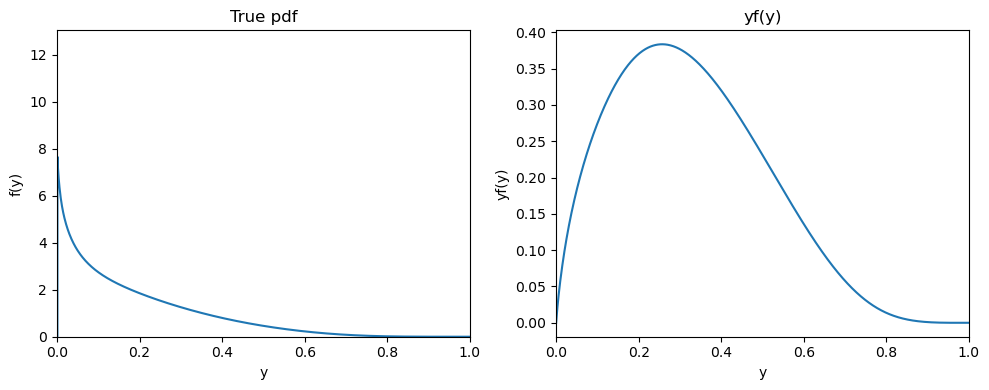

In [10]:
# plot
pt = np.linspace(x_min, x_max, 1000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(pt, f(pt))
ax1.set_xlim(0, 1)
ax1.set_ylim(0, None)
ax1.set_xlabel("y")
ax1.set_ylabel("f(y)")
ax1.set_title("True pdf")

ax2.plot(pt, pt * f(pt))
ax2.set_xlim(0, 1)
ax2.set_xlabel("y")
ax2.set_ylabel("yf(y)")
ax2.set_title("yf(y)")

plt.tight_layout()
plt.show()

## Data Generation

In [11]:
T = T_sm_FK(f=f, W=W, grid=grid)

# True c
c = 1e5

# True prediction given c
mu = true_mean(c=c, T=T, xQ2=xQ2, klin=klin, kquad=kquad)

In [12]:
# Generate data with the full covariance
rng = np.random.default_rng(seed=42)
D = rng.multivariate_normal(mean=mu, cov=Sigma)

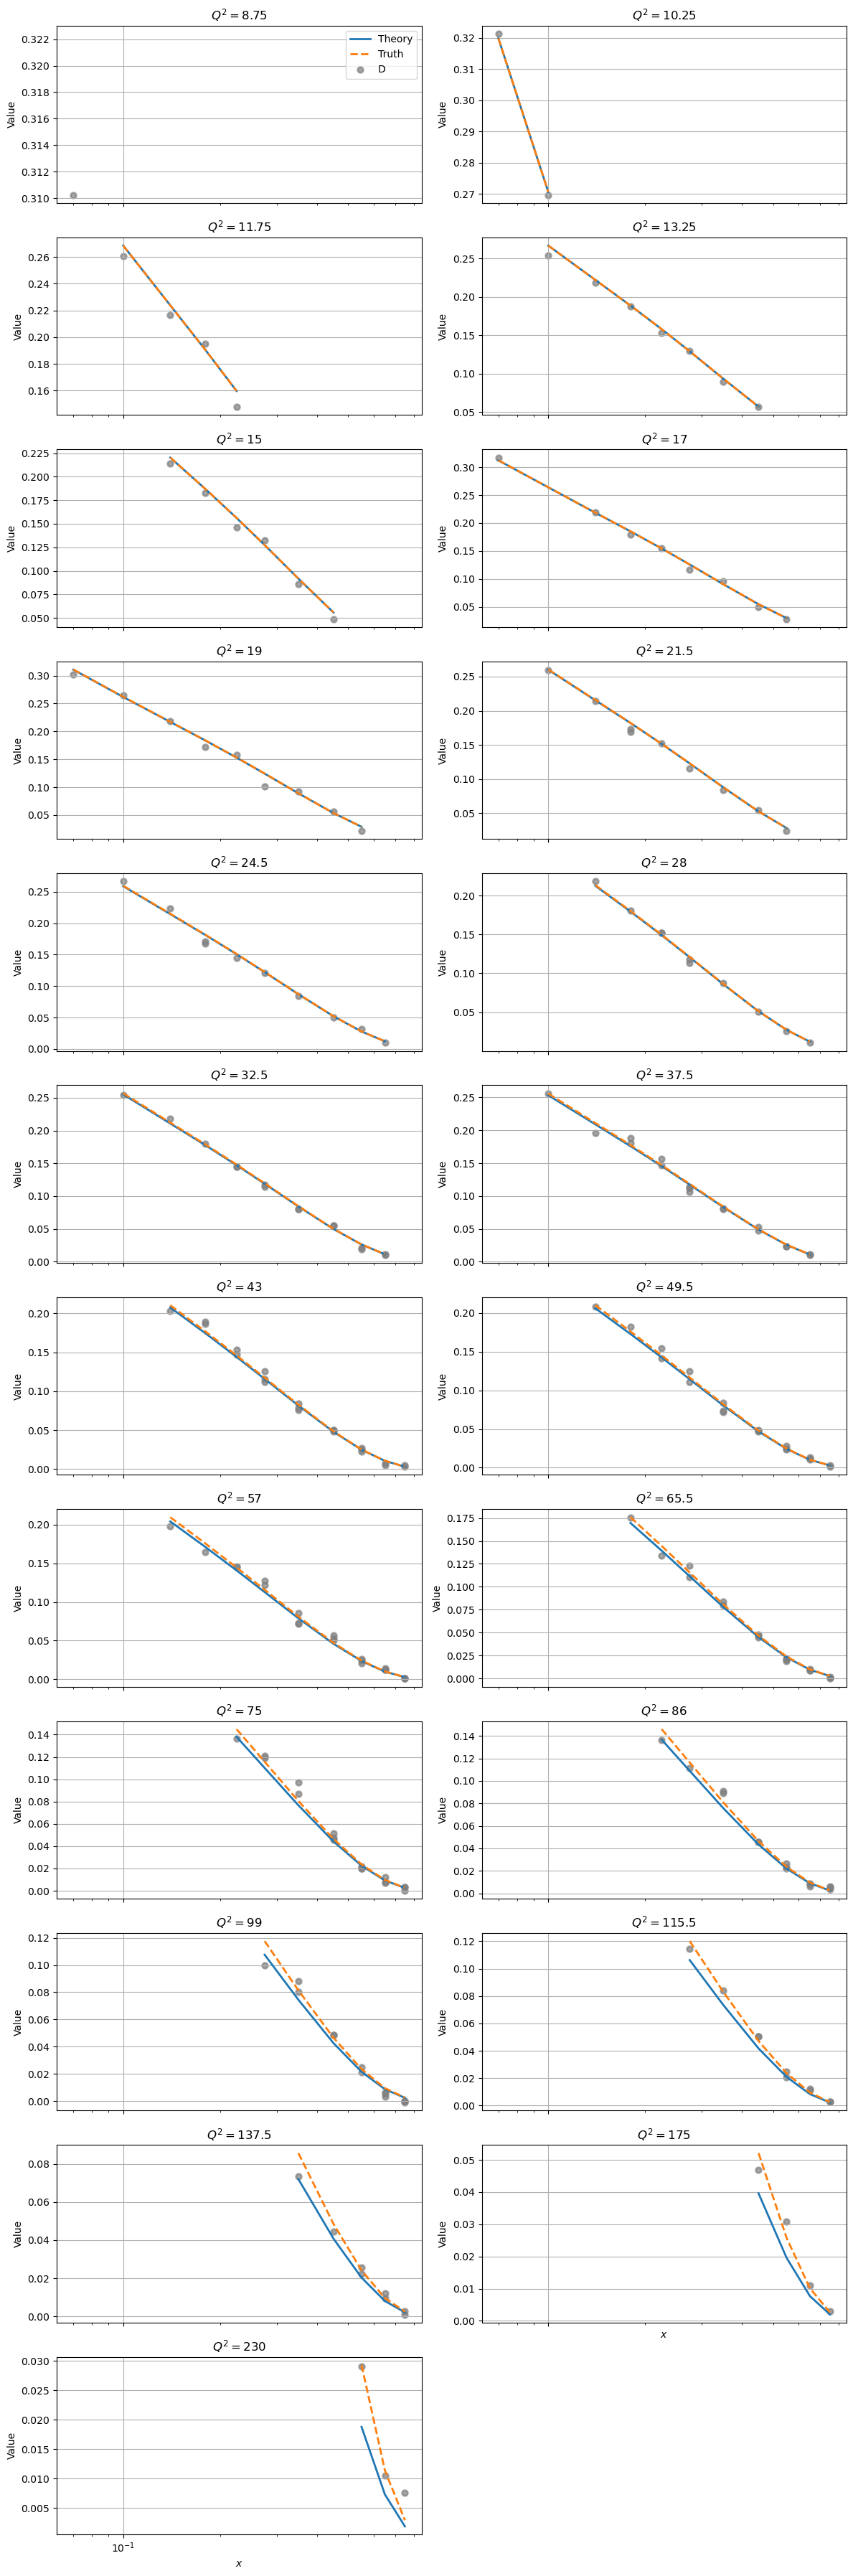

In [13]:
plot_by_Q2({"Theory": T, "Truth": mu, "D": D}, xQ2=xQ2, ncols=2, x_log_scale=True, series_styles={
    "Theory": dict(linestyle="-", linewidth=2, color="C0"),
    "Truth": dict(linestyle="--", linewidth=2, color="C1"),
    "D": dict(kind="scatter", color="gray", s=30, alpha=0.7)
})

## Estimation

In [14]:
# Specify spline basis for fitting

# Degree of B-splines
degree = 3
# Number of basis
M = 10

B = bspline_basis(degree, M, x_min, x_max)

w_norm = np.array([Bk.integrate(x_min, x_max) for Bk in B])

A = build_f_design_matrix_FK(B=B, W=W, grid=grid)

In [15]:
# fit PDF and c seperately
beta_hat, history = mle_beta(D=D, A=A, c=0, v=v_c, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, beta0=None, nonneg_beta=True, beta_opt="SLSQP", return_history=True)
c_hat = mle_c(D=D, A=A, v=v_c, beta=beta_hat, xQ2=xQ2, Sigma=Sigma, c_opt="scipy_optimize")

In [21]:
# joint fit
res, history = fit_beta_c(D=D, A=A, v=v_c, v_prime=v_prime_c, w_norm=w_norm, xQ2=xQ2, Sigma=Sigma, nonneg_beta=True,
                 return_history=True, opt_method="SLSQP")
beta_hat = res['beta_hat']
c_hat = res['c_hat']

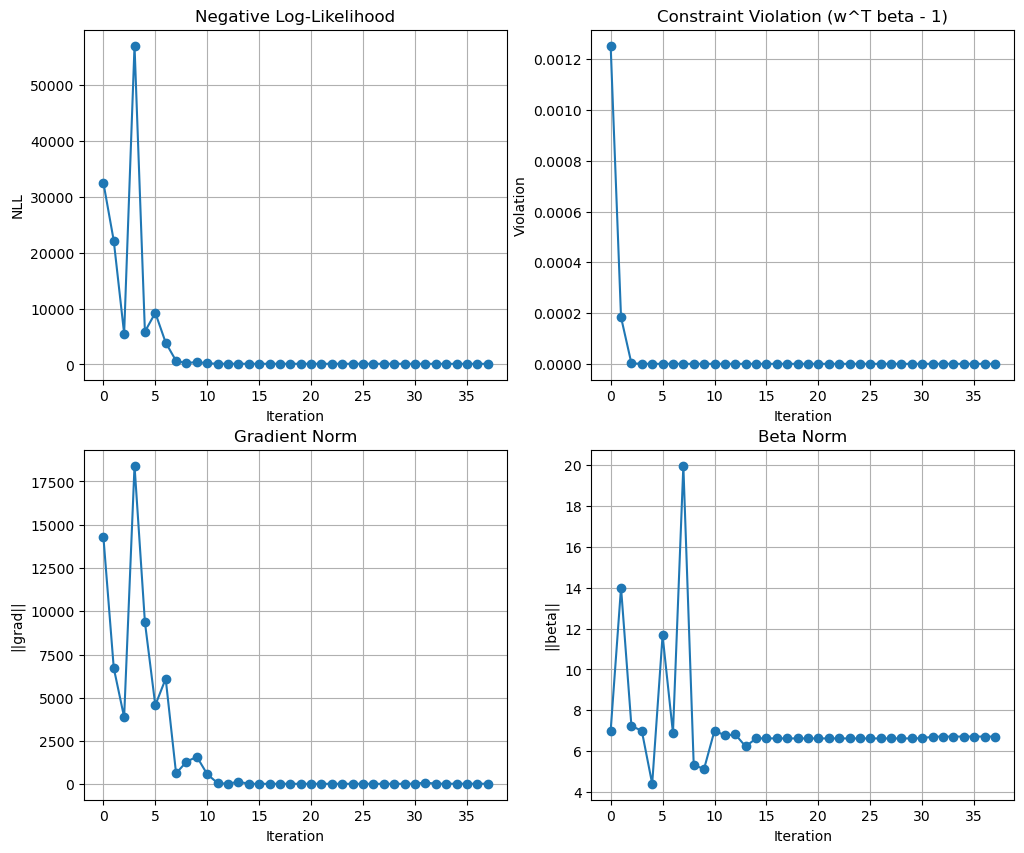

In [22]:
# Plot convergence history
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].plot(history_df['loss'], marker='o')
axes[0, 0].set_title("Negative Log-Likelihood")
axes[0, 0].set_xlabel("Iteration")
axes[0, 0].set_ylabel("NLL")
axes[0, 0].grid()

axes[0, 1].plot(history_df['constr_viol'], marker='o')
axes[0, 1].set_title("Constraint Violation (w^T beta - 1)")
axes[0, 1].set_xlabel("Iteration")
axes[0, 1].set_ylabel("Violation")
axes[0, 1].grid()

axes[1, 0].plot(history_df['grad_norm'], marker='o')
axes[1, 0].set_title("Gradient Norm")
axes[1, 0].set_xlabel("Iteration")
axes[1, 0].set_ylabel("||grad||")
axes[1, 0].grid()

axes[1, 1].plot(history_df['beta_norm'], marker='o')
axes[1, 1].set_title("Beta Norm")
axes[1, 1].set_xlabel("Iteration")
axes[1, 1].set_ylabel("||beta||")
axes[1, 1].grid()

In [23]:
mu_hat = true_mean_basis(c_hat, beta_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)

### One-step Estimator

In [24]:
K = build_K_matrix(c_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)
K_prime = build_K_prime_matrix(c_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)

In [25]:
c_one_step, info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=Sigma)

In [26]:
# print results
print("plug-in c estimate:", c_hat)
print("One-step c estimate:", c_one_step)
print("EIF:", info['eif'])

plug-in c estimate: 92508.11439409928
One-step c estimate: 95759.08414001494
EIF: 3250.9697459156596


## Plot the results

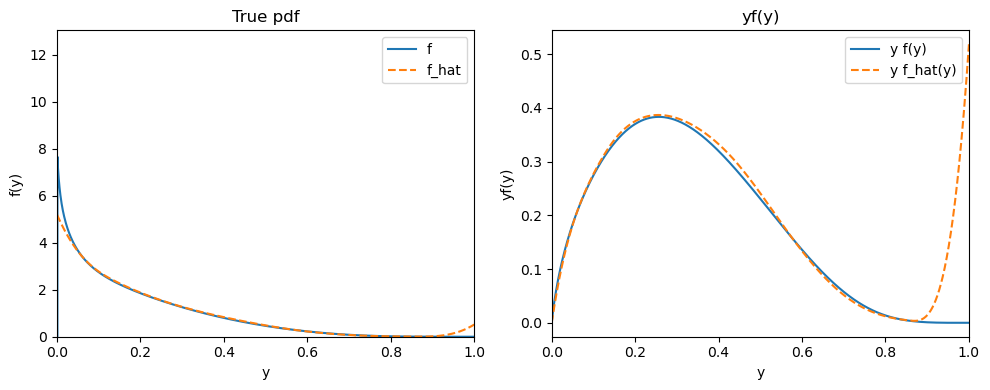

In [27]:
# plot
pt = np.linspace(x_min, x_max, 1000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

f_hat = np.zeros_like(pt, dtype=float)
for betak, Bk in zip(beta_hat, B):
    f_hat += betak * Bk(pt)

ax1.plot(pt, f(pt), label="f")
ax1.plot(pt, f_hat, linestyle="--", label="f_hat")
ax1.set_xlim(0, 1)
ax1.set_ylim(0, None)
ax1.set_xlabel("y")
ax1.set_ylabel("f(y)")
ax1.set_title("True pdf")
ax1.legend()

ax2.plot(pt, pt * f(pt), label="y f(y)")
ax2.plot(pt, pt * f_hat, linestyle="--", label="y f_hat(y)")
ax2.set_xlim(0, 1)
ax2.set_xlabel("y")
ax2.set_ylabel("yf(y)")
ax2.set_title("yf(y)")
ax2.legend()


plt.tight_layout()
plt.show()

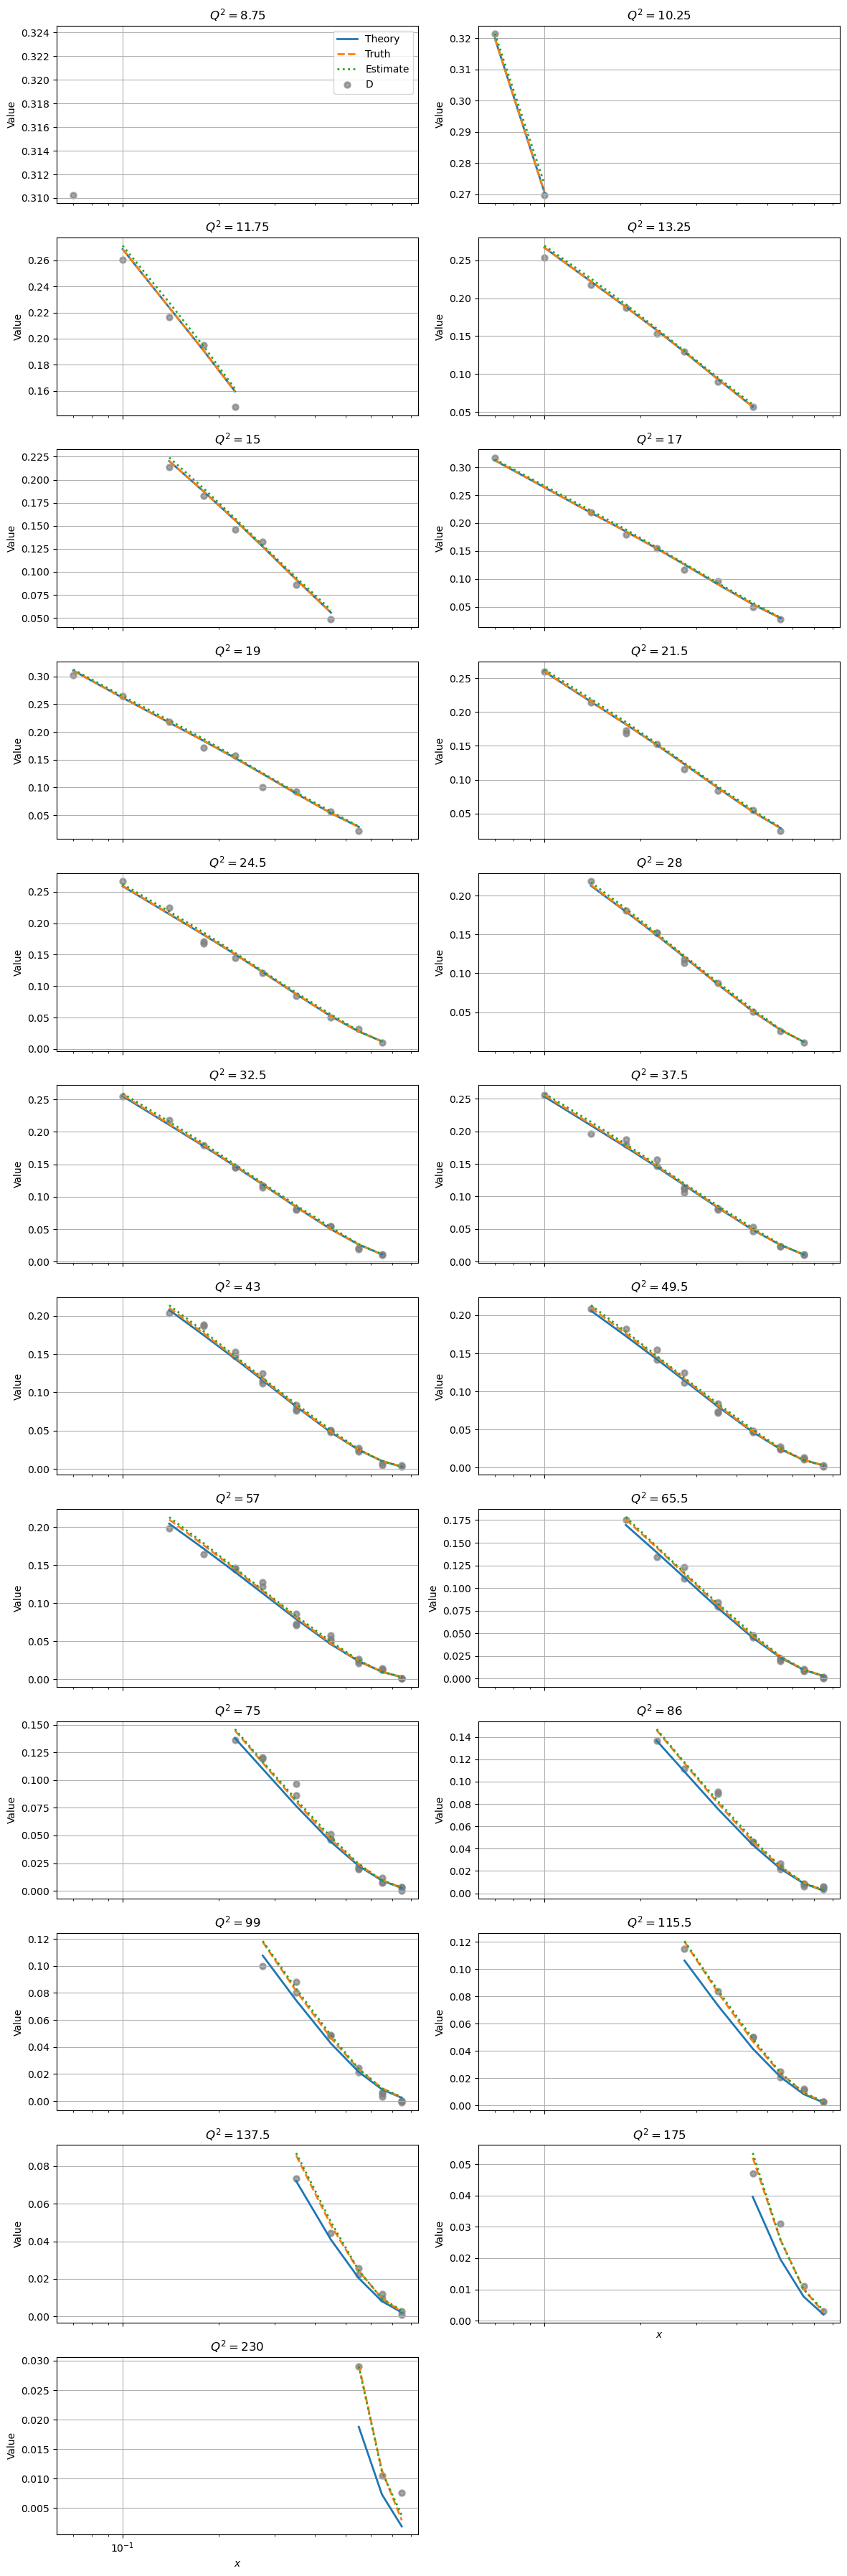

In [28]:
plot_by_Q2({"Theory": T, "Truth": mu, "Estimate": mu_hat, "D": D}, xQ2=xQ2, ncols=2, x_log_scale=True, series_styles={
    "Theory": dict(linestyle="-", linewidth=2, color="C0"),
    "Truth": dict(linestyle="--", linewidth=2, color="C1"),
    "Estimate": dict(linestyle=":", linewidth=2, color="C2"),
    "D": dict(kind="scatter", color="gray", s=30, alpha=0.7)
})

## Experiment

In [29]:
def setup_experiment(pdf, c, f, xQ2, grid, degree, M, data_var=None, data_Sigma=None, opt="joint",
                    c_opt="scipy_optimize", beta_opt="SLSQP", Lambda=Lambda, c0=0.0, beta0=None, 
                    x_min=x_min, x_max=x_max, Q2_min=Q2_min, Q2_max=Q2_max, klin=klin, kquad=kquad, 
                    nonneg_beta=True, ncol_plots=4, x_log_scale=True,
                    parametrize="f", return_history=False, loss_scale=1):
    """
    One-time setup for experiment: compute basis, smearing matrix, and true mean.
    These quantities don't change across simulations.

    Parameters
    ----------
    pdf: str
        PDF set name.
    c : float
        True c.
    f : callable
        True PDF f(y).
    xQ2 : (N,2) array
        Grid points for x and Q^2.
    grid : (N,) array
        Grid points for the FK table.
    data_var : float
        Variance of the data noise.
    data_Sigma : (N, N) array
        Covariance matrix of the data noise.
    degree : int
        Degree of B-spline basis.
    M : int
        Number of basis functions.
    opt : str, optional
        Optimization method ("joint", "separate", or "ca").
    c_opt : str, optional
        Optimization method for c ("scipy_optimize" or "grid_search").
    beta_opt : str, optional
        Optimization method for beta ("SLSQP", "trust-constr", or "closed_form").
    c0: float, optional
        Initial guess for c when using separate optimization or coordinate ascent.
    beta0: (M,) array, optional
        Initial guess for beta when using coordinate ascent.
    Lambda : float, optional
        Suppresing factor.
    x_min : float, optional
        Minimum x value for the basis.
    x_max : float, optional
        Maximum x value for the basis.
    Q2_min : float, optional
        Minimum Q^2.
    Q2_max : float, optional
        Maximum Q^2.
    klin : callable, optional
        First order polynomial coefficient.
    kquad : callable, optional
        Second order polynomial coefficient.
    nonneg_beta : bool, optional
        If True, enforce non-negativity constraint on beta.
    ncol_plots : int, optional
        Number of columns for plots.
    x_log_scale : bool, optional
        If True, use logarithmic scale for x-axis in plots.
    parametrize : str, optional
        PDF parametrization: "f" fits f(y) directly (basis expands f),
        "yf" fits yf(y) (basis expands y*f(y), so f(y) = basis/y).
    return_history : bool, optional
        If True, return optimization history for diagnostics.
    loss_scale : float, optional
        Scale factor for the loss function (default 1).


    Returns
    -------
    dict
        Setup information including B, A, w_norm, T, mu, and other parameters.
    """
    if parametrize not in ("f", "yf"):
        raise ValueError(f"parametrize must be 'f' or 'yf', got {parametrize!r}")
    if data_var is None and data_Sigma is None:
        raise ValueError("Must specify either data_var or data_Sigma.")

    # define local klin and kquad that uses the provided Lambda, Q2_min, Q2_max
    klin_local = lambda x: klin(x, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max)
    kquad_local = lambda x: kquad(x, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max)

    # --- Smeared PDF T and mean mu (true values) ---
    T = T_sm_FK(f=f, W=W, grid=grid)

    mu = true_mean(c=c, T=T, xQ2=xQ2, klin=klin_local, kquad=kquad_local)

    # --- Basis and smearing matrix ---
    B = bspline_basis(degree, M, x_min, x_max)

    if parametrize == "f":
        w_norm = np.array([Bk.integrate(x_min, x_max) for Bk in B])
        A = build_f_design_matrix_FK(B=B, W=W, grid=grid)
    else:  # "yf"
        w_norm = np.array([quad(lambda y, Bk=Bk: Bk(y) / y, x_min, x_max)[0] for Bk in B])
        A = build_yf_design_matrix_FK(B=B, W=W, grid=grid)

    return {
        'PDF': pdf,
        'B': B,
        'A': A,
        'w_norm': w_norm,
        'T': T,
        'mu': mu,
        'c': c,
        'f': f,
        'xQ2': xQ2,
        'Lambda': Lambda,
        'M': M,
        'degree': degree,
        'data_var': data_var,
        'data_Sigma': data_Sigma,
        'x_min': x_min,
        'x_max': x_max,
        'Q2_min': Q2_min,
        'Q2_max': Q2_max,
        'klin': klin_local,
        'kquad': kquad_local,
        'opt': opt,
        'c_opt': c_opt,
        'beta_opt': beta_opt,
        'c0': c0,
        'beta0': beta0,
        'nonneg_beta': nonneg_beta,
        'ncol_plots': ncol_plots,
        'x_log_scale': x_log_scale,
        'parametrize': parametrize,
        'return_history': return_history,
        "loss_scale": loss_scale,
    }


def run_single_experiment(setup_dict, diagnostics=False):
    """
    Run a single experiment with precomputed setup.
    Only generates new data and runs estimation.

    Parameters
    ----------
    setup_dict : dict
        Dictionary returned by setup_experiment().
    diagnostics : bool, optional
        If True, print diagnostic information and plots.

    Returns
    -------
    c_hat : float
        MLE estimate of c.
    c_one_step : float
        One-step corrected estimate of c.
    info : dict (only if diagnostics=True)
        Additional diagnostic information.
    """
    # Extract precomputed quantities
    A = setup_dict['A']
    B = setup_dict['B']
    w_norm = setup_dict['w_norm']
    mu = setup_dict['mu']
    T = setup_dict['T']
    c = setup_dict['c']
    f = setup_dict['f']
    xQ2 = setup_dict['xQ2']
    M = setup_dict['M']
    data_var = setup_dict['data_var']
    data_Sigma = setup_dict['data_Sigma']
    x_min = setup_dict['x_min']
    x_max = setup_dict['x_max']
    klin = setup_dict['klin']
    kquad = setup_dict['kquad']
    _v_c = lambda c, xQ2: v_c(c, xQ2, klin=klin, kquad=kquad)
    _v_prime_c = lambda c, xQ2: v_prime_c(c, xQ2, klin=klin, kquad=kquad)
    opt = setup_dict['opt']
    c_opt = setup_dict['c_opt']
    beta_opt = setup_dict['beta_opt']
    c0 = setup_dict['c0']
    beta0 = setup_dict['beta0']
    nonneg_beta = setup_dict['nonneg_beta']
    ncol_plots = setup_dict['ncol_plots']
    x_log_scale = setup_dict['x_log_scale']
    parametrize = setup_dict['parametrize']
    return_history = setup_dict['return_history']
    loss_scale = setup_dict['loss_scale']

    # =========================
    # Generate new data
    # =========================
    if data_Sigma is not None:
        rng = np.random.default_rng(seed=None)  # use a different seed for each run
        D = rng.multivariate_normal(mean=mu, cov=data_Sigma)
    else:
        D = mu + np.sqrt(data_var) * np.random.randn(len(mu))
        data_Sigma = np.eye(len(mu)) * data_var

    # =========================
    # MLE fitting
    # =========================
    if opt == "joint":
        if return_history:
            res, history = fit_beta_c(D, A, _v_c, _v_prime_c, w_norm, xQ2, Sigma=data_Sigma, nonneg_beta=nonneg_beta, opt_method=beta_opt, return_history=True, loss_scale=loss_scale)
        else:
            res = fit_beta_c(D, A, _v_c, _v_prime_c, w_norm, xQ2, Sigma=data_Sigma, nonneg_beta=nonneg_beta, opt_method=beta_opt, return_history=False, loss_scale=loss_scale)
        beta_hat = res['beta_hat']
        c_hat = res['c_hat']
    elif opt == "separate":
        if return_history:
            beta_hat, history = mle_beta(D=D, A=A, c=c0, v=_v_c, xQ2=xQ2, Sigma=data_Sigma, w_norm=w_norm, beta0=None, nonneg_beta=nonneg_beta, beta_opt=beta_opt, return_history=True, loss_scale=loss_scale)
        else:
            beta_hat = mle_beta(D=D, A=A, c=c0, v=_v_c, xQ2=xQ2, Sigma=data_Sigma, w_norm=w_norm, beta0=None, nonneg_beta=nonneg_beta, beta_opt=beta_opt, return_history=False, loss_scale=loss_scale)
        c_hat = mle_c(D=D, A=A, v=_v_c, beta=beta_hat, xQ2=xQ2, Sigma=data_Sigma, c_opt=c_opt)
        res = {'beta_hat': beta_hat, 'c_hat': c_hat}
    else:
        raise ValueError(f"Invalid opt method: {opt!r}")      
    
    mu_hat = true_mean_basis(c_hat, beta_hat, A, xQ2, klin=klin, kquad=kquad)

    # =========================
    # One-step update
    # =========================
    K = build_K_matrix(c_hat, A, xQ2, klin=klin, kquad=kquad)
    K_prime = build_K_prime_matrix(c_hat, A, xQ2, klin=klin, kquad=kquad)
    if data_Sigma is not None:
        c_one_step, one_step_info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=data_Sigma)
    else:
        c_one_step, one_step_info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, s2_diag=np.full(len(D), data_var))
    mu_one_step = true_mean_basis(c_one_step, beta_hat, A, xQ2, klin=klin, kquad=kquad)

    # =========================
    # Diagnostics (visual)
    # =========================
    if diagnostics:
        info = {}
  
        # ---- (1) PDF fit ----
        y_eval = np.linspace(x_min, x_max, 5000)
        basis_fit = sum(b * Bk(y_eval) for b, Bk in zip(beta_hat, B))

        if parametrize == "f":
            fy_fit = basis_fit           # basis expands f directly
        else:  # "yf"
            fy_fit = basis_fit / y_eval  # basis expands yf, so f = basis/y

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        #  f(y) 
        axes[0].plot(y_eval, f(y_eval), lw=2.5, label="True $f(y)$")
        axes[0].plot(y_eval, fy_fit, lw=2.5, ls="--", label="Fitted $\\hat f(y)$")
        axes[0].set_title("PDF fit")
        axes[0].set_xlabel("y")
        axes[0].set_ylabel("f(y)")
        axes[0].grid(True, color="0.85", linewidth=1.0)
        axes[0].legend()

        #  y f(y) 
        axes[1].plot(y_eval, y_eval * f(y_eval), lw=2.5, label="True $y f(y)$")
        axes[1].plot(y_eval, y_eval * fy_fit, lw=2.5, ls="--", label="Fitted $y \\hat f(y)$")
        axes[1].set_title("PDF fit")
        axes[1].set_xlabel("y")
        axes[1].set_ylabel("$y f(y)$")
        axes[1].grid(True, color="0.85", linewidth=1.0)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

        # ---- (2) Mean fit by Q^2 ----
        plot_by_Q2({"T": T, "mu": mu, "mu_hat": mu_hat, "mu_one_step": mu_one_step, "Data": D}, xQ2=xQ2, ncols=ncol_plots, x_log_scale=x_log_scale, series_styles={
            "T": dict(linestyle="-", linewidth=3, color="C0"),
            "mu": dict(linestyle="--", linewidth=3, color="C1"),
            "mu_hat": dict(linestyle=":", linewidth=3, color="C2"),
            "mu_one_step": dict(linestyle="-.", linewidth=3, color="C3"),
            "Data": dict(kind="scatter", color="gray", s=30, alpha=0.7)
        })
                
        # ---- (3) Convergence history ----
        if return_history:
            # Plot convergence history
            history_df = pd.DataFrame(history)
            fig, axes = plt.subplots(2, 2, figsize=(12, 10))
            axes[0, 0].plot(history_df['loss'], marker='o')
            axes[0, 0].set_title("Negative Log-Likelihood")
            axes[0, 0].set_xlabel("Iteration")
            axes[0, 0].set_ylabel("NLL")
            axes[0, 0].grid()

            axes[0, 1].plot(history_df['constr_viol'], marker='o')
            axes[0, 1].set_title("Constraint Violation (w^T beta - 1)")
            axes[0, 1].set_xlabel("Iteration")
            axes[0, 1].set_ylabel("Violation")
            axes[0, 1].grid()

            axes[1, 0].plot(history_df['grad_norm'], marker='o')
            axes[1, 0].set_title("Gradient Norm")
            axes[1, 0].set_xlabel("Iteration")
            axes[1, 0].set_ylabel("||grad||")
            axes[1, 0].grid()

            axes[1, 1].plot(history_df['beta_norm'], marker='o')
            axes[1, 1].set_title("Beta Norm")
            axes[1, 1].set_xlabel("Iteration")
            axes[1, 1].set_ylabel("||beta||")
            axes[1, 1].grid()

        # ---- Numerical table ----
        results_df = pd.DataFrame({
            "Parameter": ["c_hat", "c_one_step", "True c"] + [f"beta_{m}" for m in range(M)],
            "Value": np.concatenate([[c_hat, c_one_step, c], beta_hat])
        })
        print(results_df.round(6))

        # check normalization constraint
        print("Normalization constraint (w^T beta_hat):", float(w_norm @ beta_hat))
        # check fitted pdf is a valid density
        fy_integral = fixed_quad(lambda y: sum(b * Bk(y) for b, Bk in zip(beta_hat, B)) / (y if parametrize == "yf" else 1.0),
                                 x_min, x_max, n=1000)[0]
        print(f"Fitted pdf integrates to ({parametrize} parametrize):", fy_integral)

        info['mle'] = res
        info['one_step'] = one_step_info
        return c_hat, c_one_step, info
    else:
        return c_hat, c_one_step


def experiment(c, f, xQ2, grid, degree, M, data_var=None, data_Sigma=None, opt="joint", 
               c_opt="scipy_optimize", beta_opt="SLSQP", c0=0.0, beta0=None,
               Lambda=Lambda, x_min=x_min, x_max=x_max, Q2_min=Q2_min, Q2_max=Q2_max, klin=klin, kquad=kquad, 
               nonneg_beta=True, diagnostics=False, ncol_plots=4, x_log_scale=True,
               parametrize="f", return_history=False):
    """
    Run a full experiment with data generation, MLE fitting, and one-step update.

    This is a convenience wrapper that calls setup_experiment() and run_single_experiment().
    For simulations, use setup_experiment() once, then call run_single_experiment() repeatedly.

    Parameters
    ----------
    c : float
        True c.
    f : callable
        True PDF f(y).
    xQ2 : (n_xQ2,) array
        Grid points for x and Q^2.
    grid : (N,) array
        Grid points for the FK table.
    data_var : float
        Variance of the data noise.
    data_Sigma : (N, N) array
        Covariance matrix of the data noise. If specified, overrides data_var.
    degree : int
        Degree of B-spline basis.
    M : int
        Number of basis functions.
    opt : str, optional
        Optimization method ("joint", "separate", or "ca").
    c_opt : str, optional
        Optimization method for c ("scipy_optimize" or "grid_search").
    beta_opt : str, optional
        Optimization method for beta ("SLSQP" or "closed_form").
    c0: float, optional
        Initial guess for c when using separate optimization or coordinate ascent.
    beta0: (M,) array, optional
        Initial guess for beta when using coordinate ascent.
    Lambda : float, optional
        Suppresing factor.
    x_min : float, optional
        Minimum x value for the basis.
    x_max : float, optional
        Maximum x value for the basis.
    Q2_min : float, optional
        Minimum Q^2.
    Q2_max : float, optional
        Maximum Q^2.
    klin : callable, optional
        first order of polynomial coefficient.
    kquad : callable, optional
        second order of polynomial coefficient.
    sigma_NLO : callable, optional
        NLO part of the smearing kernel
    nonneg_beta : bool, optional
        If True, enforce non-negativity constraint on beta.
    diagnostics : bool, optional
        If True, print diagnostic information.
    ncol_plots : int, optional
        Number of columns for plots.
    x_log_scale : bool, optional
        If True, use logarithmic scale for x-axis in plots.
    parametrize : str, optional
        PDF parametrization: "f" fits f(y) directly, "yf" fits y*f(y).
    return_history : bool, optional
        If True, return optimization history for diagnostics.

    Returns
    -------
    dict
        Results including fitted beta, c, one-step c, and diagnostics.
    """

    setup_dict = setup_experiment(c=c, f=f, xQ2=xQ2, grid=grid,
                                  data_var=data_var, data_Sigma=data_Sigma, degree=degree, M=M, opt=opt, 
                                  c_opt=c_opt, beta_opt=beta_opt, c0=c0, beta0=beta0,
                                  Lambda=Lambda, x_min=x_min, x_max=x_max, Q2_min=Q2_min, Q2_max=Q2_max,
                                  klin=klin, kquad=kquad,
                                  nonneg_beta=nonneg_beta, ncol_plots=ncol_plots, x_log_scale=x_log_scale,
                                  parametrize=parametrize, return_history=return_history)
    return run_single_experiment(setup_dict, diagnostics)


In [30]:
setup_dict = setup_experiment(pdf=pdfset, c=1e5, f=f, xQ2=xQ2, grid=grid,
                                  data_var=None, data_Sigma=Sigma, degree=3, M=10, opt="separate", parametrize="f",
                                  c_opt="scipy_optimize", beta_opt="SLSQP", c0=0, beta0=None,
                                  Lambda=500, x_min=x_min, x_max=x_max, Q2_min=Q2_min, Q2_max=Q2_max,
                                  klin=klin, kquad=kquad,
                                  nonneg_beta=True, ncol_plots=2, 
                                  x_log_scale=False, return_history=True, loss_scale=1)

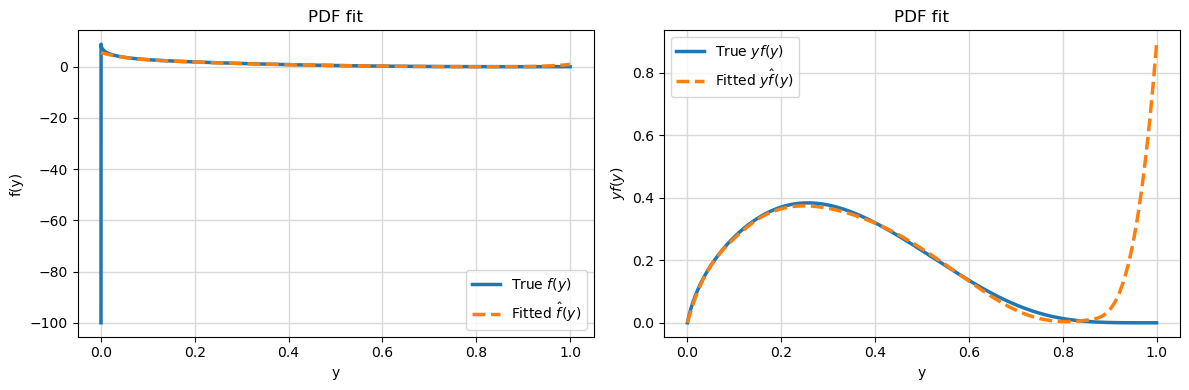

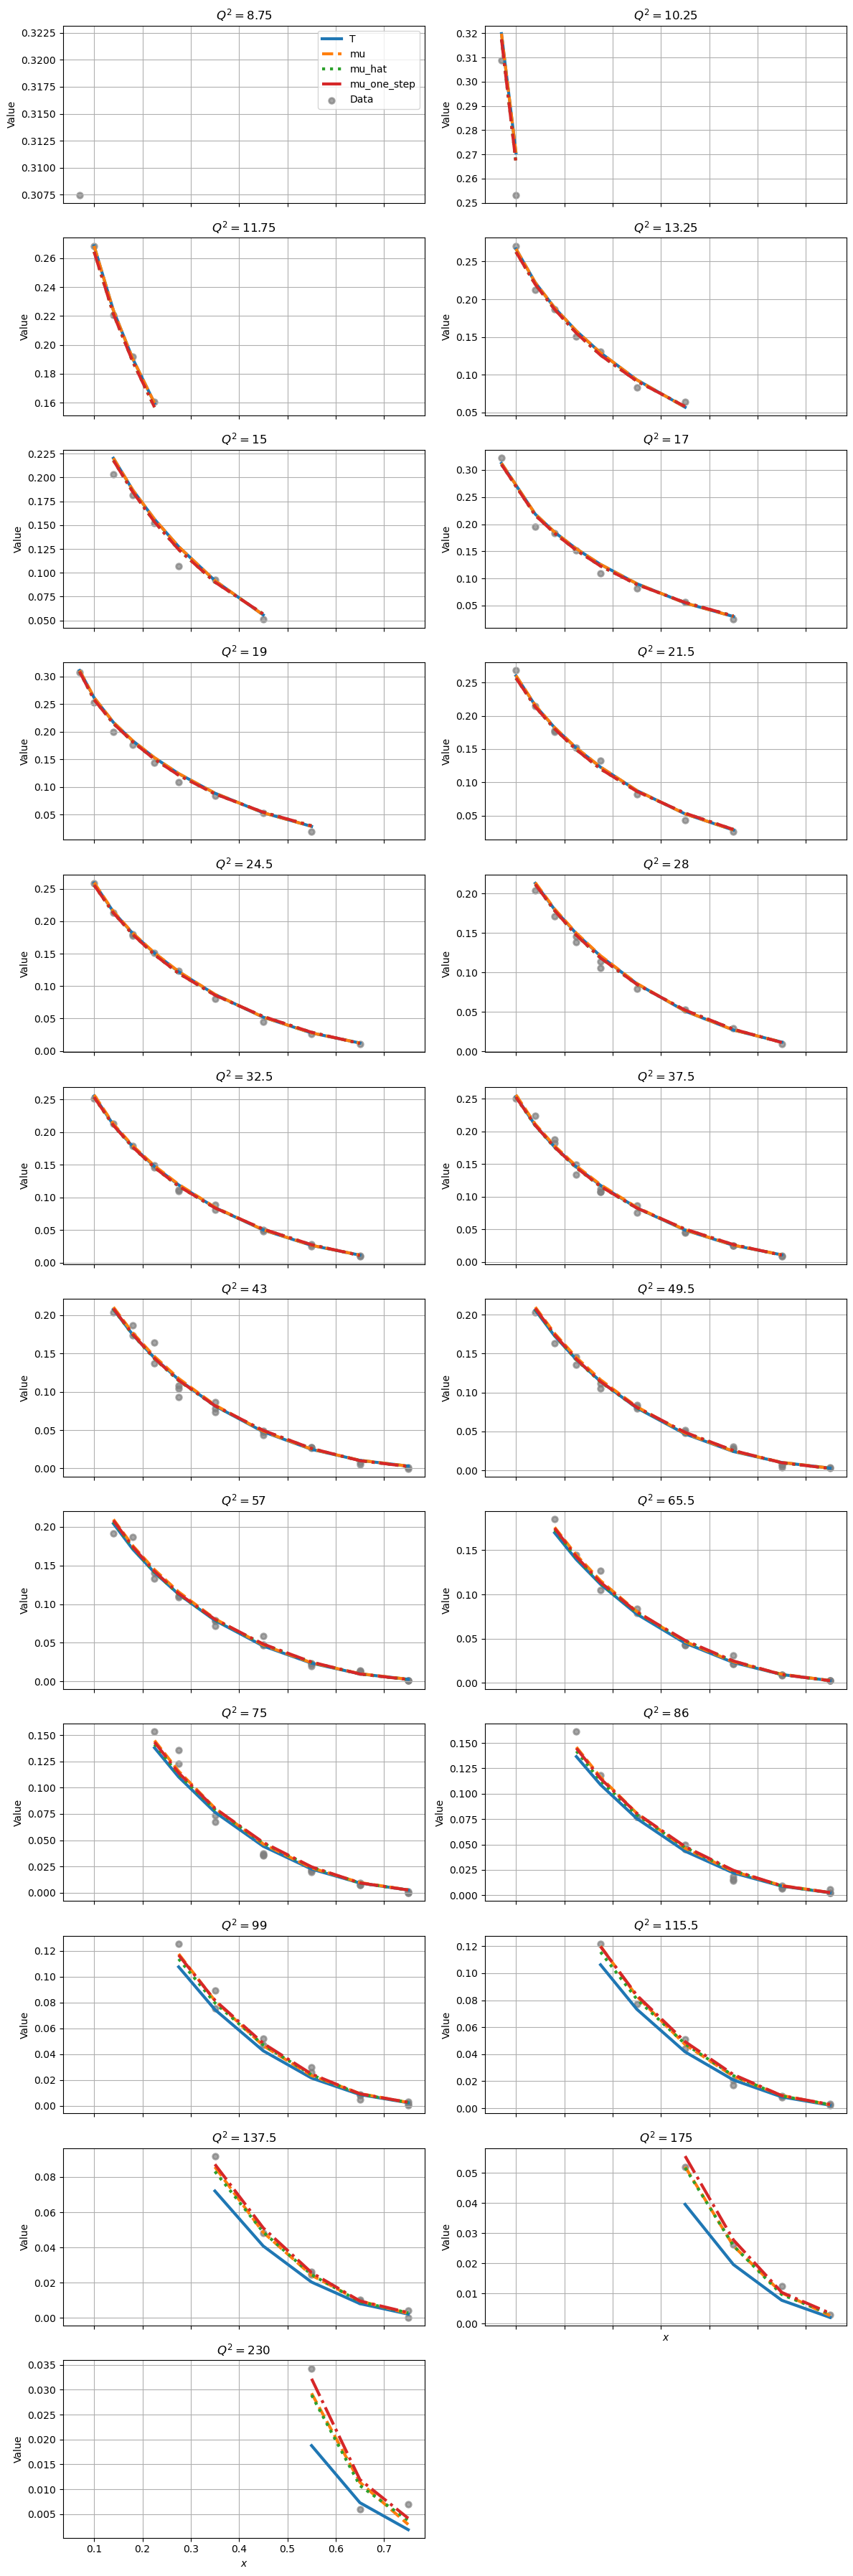

     Parameter          Value
0        c_hat   89462.850506
1   c_one_step  112703.070118
2       True c  100000.000000
3       beta_0       5.499537
4       beta_1       3.163910
5       beta_2       2.181118
6       beta_3       1.228586
7       beta_4       0.672458
8       beta_5       0.261246
9       beta_6       0.000000
10      beta_7       0.000000
11      beta_8       0.044643
12      beta_9       0.890839
Normalization constraint (w^T beta_hat): 1.0000000000001186
Fitted pdf integrates to (f parametrize): 1.0000000000077387


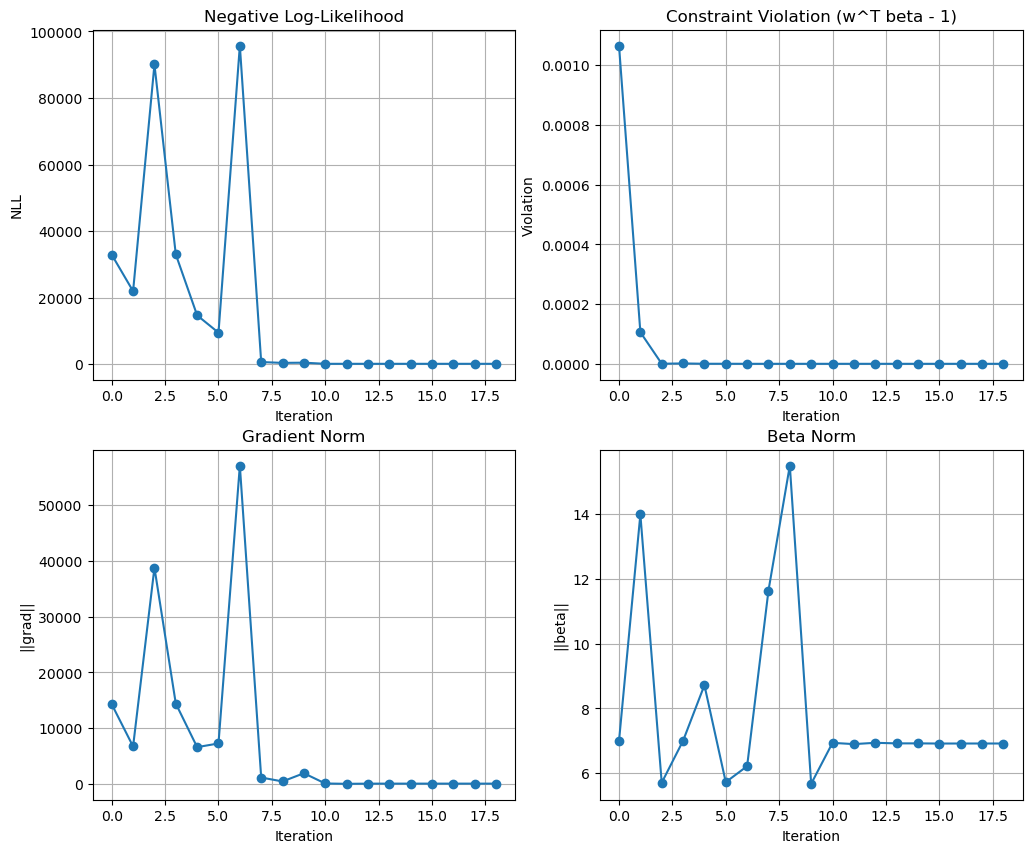

In [31]:
c_hat, c_one_step, info = run_single_experiment(setup_dict, diagnostics=True)

## Simulation

In [32]:
N_sim = 100
plug_in_estimates = np.zeros(N_sim, dtype=float)
one_step_estimates = np.zeros(N_sim, dtype=float)

for sim in range(N_sim):
    print(f"Simulation {sim+1}/{N_sim}")
    c_hat, c_one_step = run_single_experiment(setup_dict, 
                                               diagnostics=False)
    plug_in_estimates[sim] = c_hat
    one_step_estimates[sim] = c_one_step

print("\nResults:")
print(f"Plug-in estimates: mean={plug_in_estimates.mean():.4f}, median={np.median(plug_in_estimates):.4f}, bias={plug_in_estimates.mean() - setup_dict['c']:.4f}, std={plug_in_estimates.std():.4f}")
print(f"One-step estimates: mean={one_step_estimates.mean():.4f}, median={np.median(one_step_estimates):.4f}, bias={one_step_estimates.mean() - setup_dict['c']:.4f}, std={one_step_estimates.std():.4f}")
print(f"True c: {setup_dict['c']}")

Simulation 1/100
Simulation 2/100
Simulation 3/100
Simulation 4/100
Simulation 5/100
Simulation 6/100
Simulation 7/100
Simulation 8/100
Simulation 9/100
Simulation 10/100
Simulation 11/100
Simulation 12/100
Simulation 13/100
Simulation 14/100
Simulation 15/100
Simulation 16/100
Simulation 17/100
Simulation 18/100
Simulation 19/100
Simulation 20/100
Simulation 21/100
Simulation 22/100
Simulation 23/100
Simulation 24/100
Simulation 25/100
Simulation 26/100
Simulation 27/100
Simulation 28/100
Simulation 29/100
Simulation 30/100
Simulation 31/100
Simulation 32/100
Simulation 33/100
Simulation 34/100
Simulation 35/100
Simulation 36/100
Simulation 37/100
Simulation 38/100
Simulation 39/100
Simulation 40/100
Simulation 41/100
Simulation 42/100
Simulation 43/100
Simulation 44/100
Simulation 45/100
Simulation 46/100
Simulation 47/100
Simulation 48/100
Simulation 49/100
Simulation 50/100
Simulation 51/100
Simulation 52/100
Simulation 53/100
Simulation 54/100
Simulation 55/100
Simulation 56/100
S

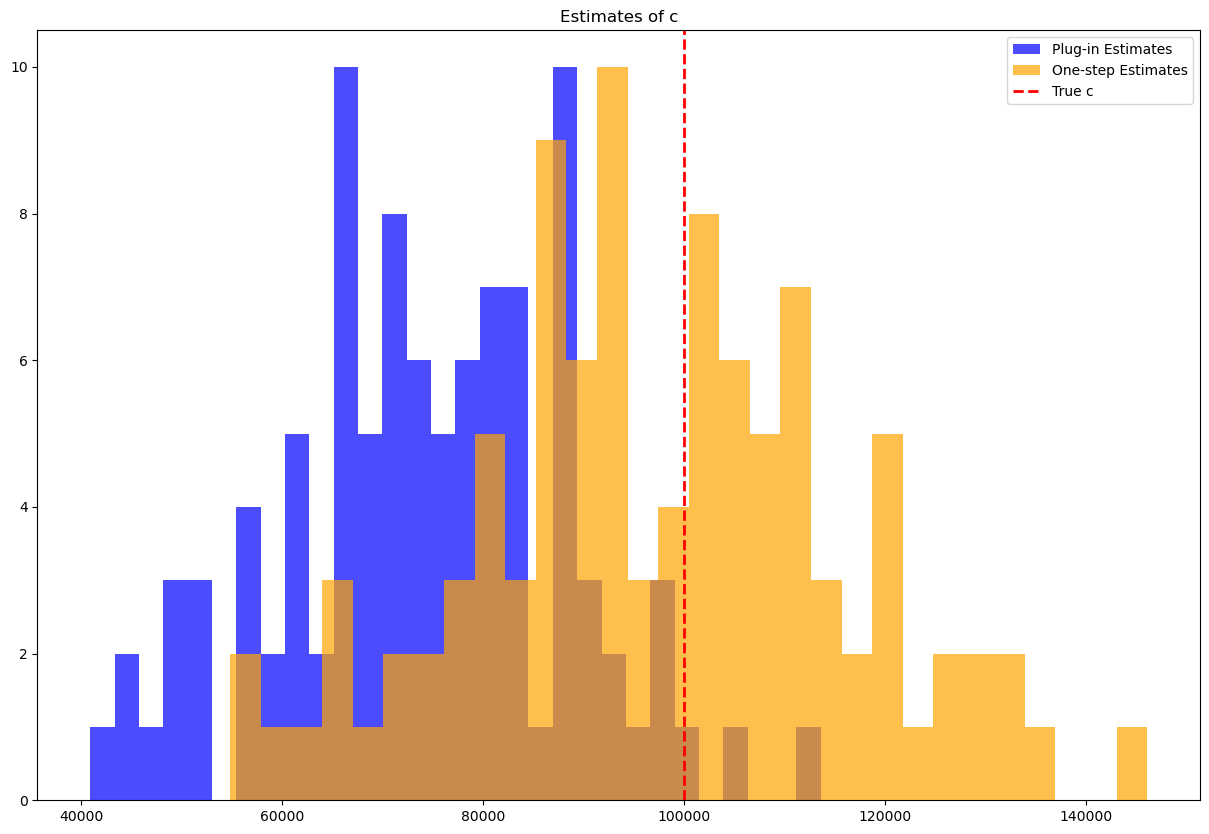

In [33]:
# plot the histograms of the estimates
plt.figure(figsize=(15,10))
plt.hist(plug_in_estimates, bins=30, alpha=0.7, color='blue', label='Plug-in Estimates')
plt.hist(one_step_estimates, bins=30, alpha=0.7, color='orange', label='One-step Estimates')
plt.axvline(setup_dict['c'], color='red', linestyle='dashed', linewidth=2, label='True c')
plt.title("Estimates of c")
plt.legend()